In [45]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from ydata_profiling import ProfileReport
%matplotlib inline


In [46]:
from datetime import date, timedelta
import pandas as pd
import requests

def fetch_multiple_years(lat, lon, start_date, end_date):
    all_data = []
    current_start = start_date

    while current_start < end_date:
        current_end = min(current_start + timedelta(days=364), end_date)
        print(f"Fetching: {current_start} → {current_end}")

        resp = requests.get(
            "https://archive-api.open-meteo.com/v1/archive",
            params={
                "latitude": lat,
                "longitude": lon,
                "start_date": current_start.isoformat(),
                "end_date": current_end.isoformat(),
                "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max",
                "timezone": "auto",
            }
        )
        resp.raise_for_status()
        data = resp.json().get("daily", {})
        df = pd.DataFrame(data)
        all_data.append(df)

        # Move start date forward
        current_start = current_end + timedelta(days=1)

    return pd.concat(all_data, ignore_index=True)

# Example: Try 3 years
today = date.today()
three_years_ago = today - timedelta(days=1095)

df_weather = fetch_multiple_years(
    lat=32.1617, lon=74.1883,  # Gujranwala
    start_date=three_years_ago,
    end_date=today
)

print(f"✅ Got {len(df_weather)} days of data")
print(df_weather.head())

df=df_weather

Fetching: 2022-10-08 → 2023-10-07
Fetching: 2023-10-08 → 2024-10-06
4-10-07 → 2025-10-06

✅ Got 1095 days of data
         time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0  2022-10-08                32.9                21.3                0.0   
1  2022-10-09                32.5                21.2                0.0   
2  2022-10-10                29.5                20.9                0.0   
3  2022-10-11                29.4                20.2                7.6   
4  2022-10-12                30.0                17.5                0.0   

   windspeed_10m_max  
0               11.0  
1               10.6  
2               10.2  
3               13.4  
4                8.4  


In [47]:
# ---------- WEATHER CLASSIFICATION FUNCTION ----------
def classify_weather(row):
    if pd.isna(row["temperature_2m_max"]):
        return np.nan

    temp = row["temperature_2m_max"]
    precip = row["precipitation_sum"]
    wind = row["windspeed_10m_max"]
    # 1. Stormy conditions
    if wind >= 50 and precip > 10:
        return "Stormy"

    # 2. Heavy rain
    if precip >= 10:
        return "Heavy Rain"

    # 3. Light to moderate rain
    if 1 <= precip < 10:
        return "Rainy"

    # 4. Drizzle
    if 0 < precip < 1:
        return "Drizzle"

    # 5. Snow (very low temp + precipitation)
    if precip > 0 and temp <= 3:
        return "Snow"

    # 6. Clear sunny day
    if temp >= 30 and precip == 0:
        return "Sunny"

    # 7. Cold but clear
    if temp < 10 and precip == 0:
        return "Cold & Clear"

    # 8. Default: Cloudy
    return "Cloudy"


In [48]:
df["weather"] = df_weather.apply(classify_weather, axis=1)
df['weather'].value_counts()

weather
Cloudy        348
Sunny         327
Rainy         178
Drizzle       158
Heavy Rain     84
Name: count, dtype: int64

In [49]:
cols=df.select_dtypes(include=['int','float'])
for col in cols:    
    df[col].fillna(df[col].mean(),inplace=True)
cols=df.select_dtypes(include=['category','object'])
for col in cols:    
    df[col].fillna(df[col].mode()[0],inplace=True)
df    

C:\Users\World\AppData\Local\Temp\ipykernel_16780\3862173393.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(),inplace=True)
C:\Users\World\AppData\Local\Temp\ipykernel_16780\3862173393.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

,time,temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max,weather
0,2022-10-08,32.9,21.3,0.0,11.0,Sunny
1,2022-10-09,32.5,21.2,0.0,10.6,Sunny
2,2022-10-10,29.5,20.9,0.0,10.2,Cloudy
3,2022-10-11,29.4,20.2,7.6,13.4,Rainy
4,2022-10-12,30.0,17.5,0.0,8.4,Sunny
...,...,...,...,...,...,...
1090,2025-10-02,34.3,23.2,6.5,14.8,Rainy
1091,2025-10-03,30.8,22.0,7.2,21.6,Rainy
1092,2025-10-04,31.6,22.2,6.6,17.1,Rainy
1093,2025-10-05,28.9,19.2,15.9,23.5,Heavy Rain


In [50]:
profile = ProfileReport(df, title="CLV Data Profiling Report", explorative=True)

# Show report in notebook
profile.to_notebook_iframe()


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 98.47it/s]%|                                                                                            | 0/6 [00:00<?, ?it/s]%|                                                                                            | 0/6 [00:00<?, ?it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

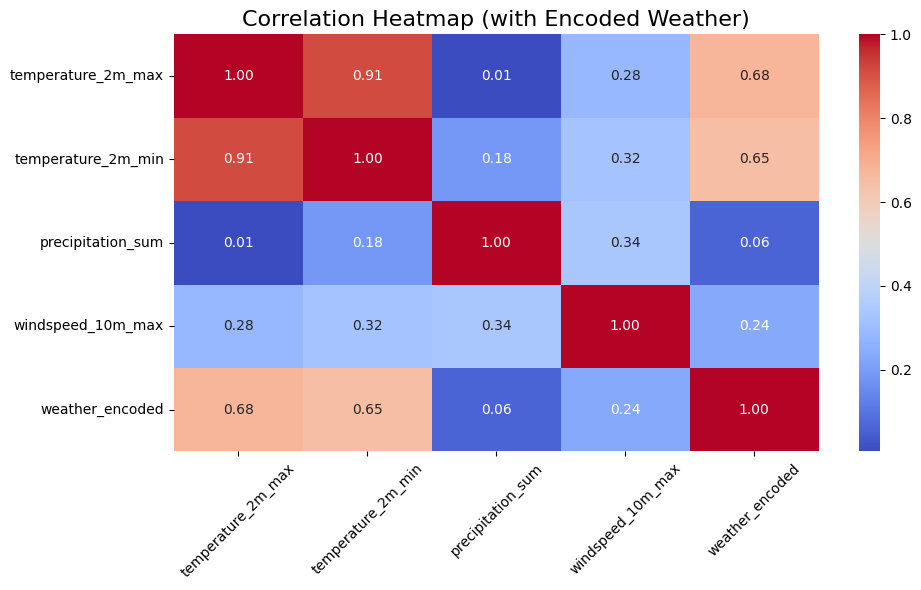

In [51]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
# Encode weather column to numeric
df['weather_encoded'] = le.fit_transform(df['weather'])

# Select numeric columns again (now weather is numeric)
numeric_df = df.select_dtypes(include=[np.number,'datetime'])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap (with Encoded Weather)", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [43]:
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import f1_score,r2_score,mean_absolute_error,mean_squared_error,accuracy_score, classification_report, confusion_matrix


In [52]:
df['time']=pd.to_datetime(df['time'])
# Extract numeric features from date
df['year'] = df['time'].dt.year
df['month'] = df['time'].dt.month
df['day'] = df['time'].dt.day
df['dayofweek'] = df['time'].dt.dayofweek

# Drop original date column
X_linear = df.drop(columns=['time', 'weather','weather_encoded'])  # assuming 'weather' is your target

# Define target (example)
y_linear = df['weather_encoded']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_linear, y_linear, test_size=0.2, random_state=42)
print(X_train)
# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# X_train_scaled,X_test_scaled,y_train

      temperature_2m_max  temperature_2m_min  precipitation_sum  \
6                   31.9                19.1                0.0   
575                 36.1                21.9                0.0   
821                 18.2                 8.3                0.0   
1063                33.2                23.5                0.0   
905                 30.7                15.2                0.0   
...                  ...                 ...                ...   
330                 35.5                26.6                0.0   
466                 15.9                 2.7                0.0   
121                 21.8                11.2                0.2   
1044                33.4                25.4                2.8   
860                 23.1                 9.0                0.0   

      windspeed_10m_max  year  month  day  dayofweek  
6                  11.9  2022     10   14          4  
575                17.7  2024      5    5          6  
821                10.6  2025 

In [53]:
LR=LinearRegression()
model=LR.fit(X_train_scaled,y_train)
model
y_pred = model.predict(X_test_scaled)
y_pred
# R² Score
r2 = r2_score(y_test, y_pred)

# MAE, MSE, RMSE
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R² Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

R² Score: 0.4039
MAE: 1.0657
MSE: 1.6326
RMSE: 1.2777


**Use LogisticRegression model for more accuracy due to categorical value**

Accuracy: 0.7945

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.89      0.86        61
           1       0.54      0.41      0.47        34
           2       1.00      0.84      0.91        19
           3       0.90      0.81      0.85        32
           4       0.77      0.88      0.82        73

    accuracy                           0.79       219
   macro avg       0.81      0.77      0.78       219
weighted avg       0.79      0.79      0.79       219



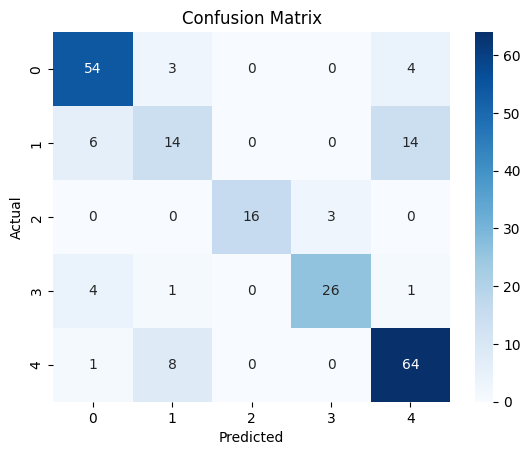

In [54]:
log_reg = LogisticRegression(max_iter=500)
log_reg.fit(X_train_scaled, y_train)

# Predict
y_pred = log_reg.predict(X_test_scaled)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [55]:
pd.concat([pd.DataFrame(X_test).reset_index(drop=True),
           pd.Series(le.inverse_transform(y_test), name="Actual_Weather")], axis=1)


,temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max,year,month,day,dayofweek,Actual_Weather
0,29.4,17.5,1.5,25.7,2024,3,24,6,Rainy
1,27.3,10.6,0.0,12.4,2023,2,24,4,Cloudy
2,15.7,3.7,0.0,10.0,2023,1,4,2,Cloudy
3,21.5,6.2,0.0,9.0,2025,1,26,6,Cloudy
4,40.1,29.6,0.1,13.0,2025,6,19,3,Drizzle
...,...,...,...,...,...,...,...,...,...
214,34.2,23.7,0.0,7.0,2024,9,18,2,Sunny
215,36.0,26.4,0.0,8.4,2023,9,4,0,Sunny
216,33.5,18.7,0.0,10.3,2023,10,4,2,Sunny
217,17.5,6.8,0.0,6.2,2025,1,2,3,Cloudy


In [56]:
### import pandas as pd

# === Show all possible weather classes ===
print("Available Weather Classes:", list(le.classes_))

# === Interactive Prediction Console ===
while True:
    print("\n--- Weather Prediction Console ---")
    try:
        # Take user input
        precipitation = float(input("Enter precipitation (e.g., 1.0): "))
        temp_max = float(input("Enter max temp (°C): "))
        temp_min = float(input("Enter min temp (°C): "))
        wind = float(input("Enter wind speed: "))
        year = int(input("Enter year (e.g., 2015): "))
        month = int(input("Enter month (1-12): "))
        day = int(input("Enter day (1-31): "))
        dayofweek = int(input("Enter dayofweek (0=Mon ... 6=Sun): "))
# temp_max  temp_min  precipitation  wind  year  month  day  dayofweek
        # Build dataframe
        new_data = pd.DataFrame([{
            'temp_max': temp_max,
            'temp_min': temp_min,
            'precipitation': precipitation,
            'wind': wind,
            'year': year,
            'month': month,
            'day': day,
            'dayofweek': dayofweek
        }])

        # Predict
        prediction = rf.predict(new_data)
        decoded_prediction = le.inverse_transform(prediction)

        print(f"\nPredicted Weather: {decoded_prediction[0]} (Class Index: {prediction[0]})")

    except Exception as e:
        print(f"Error: {e}")

    # Option to continue or exit
    cont = input("\nDo you want to predict again? (y/n): ").strip().lower()
    if cont != 'y':
        print("Exiting Prediction Console. Goodbye!")
        break
# 34.2	26.3	2.2	7.1	2025	8	3	6	Rainy

Available Weather Classes: ['Cloudy', 'Drizzle', 'Heavy Rain', 'Rainy', 'Sunny']

--- Weather Prediction Console ---


Enter precipitation (e.g., 1.0):  3.3
Enter max temp (°C):  32
in temp (°C):  21

Enter wind speed:  2
year (e.g., 2015):  2022
Enter month (1-12):  422

day (1-31):  6 422


Enter dayofweek (0=Mon ... 6=Sun):  4


Error: This RandomForestClassifier instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.



Do you want to predict again? (y/n):  n


Exiting Prediction Console. Goodbye!


Best Parameters: {'C': 100, 'class_weight': None, 'solver': 'lbfgs'}
Best Accuracy on Train CV: 0.9223766233766234
Test Accuracy: 0.8904

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.92      0.93        61
           1       0.79      0.65      0.71        34
           2       1.00      0.89      0.94        19
           3       0.94      0.94      0.94        32
           4       0.85      0.96      0.90        73

    accuracy                           0.89       219
   macro avg       0.90      0.87      0.88       219
weighted avg       0.89      0.89      0.89       219



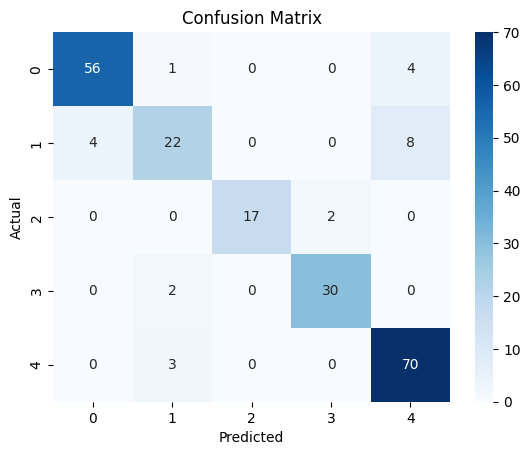

In [59]:

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # Regularization strength
    'solver': ['liblinear', 'lbfgs', 'saga'],
    'class_weight': [None, 'balanced']
}

log_reg = LogisticRegression(max_iter=1000)
grid = GridSearchCV(log_reg, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Accuracy on Train CV:", grid.best_score_)

# Evaluate on Test Data
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test_scaled)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [61]:

# === Show all possible weather classes ===
print("Available Weather Classes:", list(le.classes_))

# === Interactive Prediction Console ===
while True:
    print("\n--- Weather Prediction Console ---")
    try:
        # Take user input
        precipitation = float(input("Enter precipitation (e.g., 1.0): "))
        temp_max = float(input("Enter max temp (°C): "))
        temp_min = float(input("Enter min temp (°C): "))
        wind = float(input("Enter wind speed: "))
        year = int(input("Enter year (e.g., 2015): "))
        month = int(input("Enter month (1-12): "))
        day = int(input("Enter day (1-31): "))
        dayofweek = int(input("Enter dayofweek (0=Mon ... 6=Sun): "))
# temp_max  temp_min  precipitation  wind  year  month  day  dayofweek
        # Build dataframe
        new_data = pd.DataFrame([{
            'temp_max': temp_max,
            'temp_min': temp_min,
            'precipitation': precipitation,
            'wind': wind,
            'year': year,
            'month': month,
            'day': day,
            'dayofweek': dayofweek
        }])

        # Predict
        prediction = best_model.predict(new_data)
        decoded_prediction = le.inverse_transform(prediction)

        print(f"\nPredicted Weather: {decoded_prediction[0]} (Class Index: {prediction[0]})")

    except Exception as e:
        print(f"Error: {e}")

    # Option to continue or exit2
    cont = input("\nDo you want to predict again? (y/n): ").strip().lower()
    if cont != 'y':
        print("Exiting Prediction Console. Goodbye!")
        break
# 34.2	26.3	2.2	7.1	2025	8	3	6	Rainy

Available Weather Classes: ['Cloudy', 'Drizzle', 'Heavy Rain', 'Rainy', 'Sunny']

--- Weather Prediction Console ---


Enter precipitation (e.g., 1.0):  2
Enter max temp (°C):  3
in temp (°C):  1

Enter wind speed:  2
year (e.g., 2015):  2022
Enter month (1-12):  522

day (1-31):  4 522


Enter dayofweek (0=Mon ... 6=Sun):  4


C:\Python313\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(



Predicted Weather: Heavy Rain (Class Index: 2)



Do you want to predict again? (y/n):  n


Exiting Prediction Console. Goodbye!


Random Forest Accuracy: 0.9954337899543378
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        61
           1       0.97      1.00      0.99        34
           2       1.00      1.00      1.00        19
           3       1.00      0.97      0.98        32
           4       1.00      1.00      1.00        73

    accuracy                           1.00       219
   macro avg       0.99      0.99      0.99       219
weighted avg       1.00      1.00      1.00       219



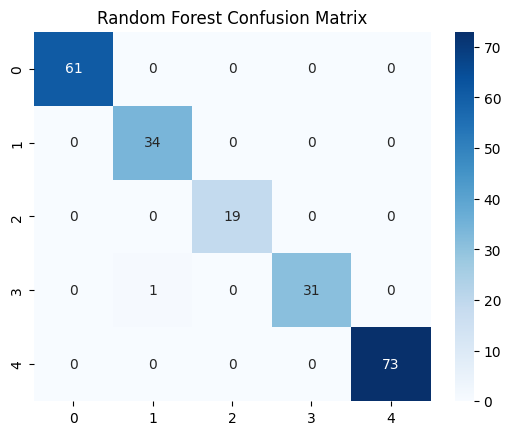

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()


In [63]:
import pandas as pd
import numpy as np
import requests
from datetime import date, timedelta
from sklearn.preprocessing import LabelEncoder

# ----------------- FETCH FUNCTION -----------------
def fetch_weather_data(lat, lon, start_date, end_date):
    all_data = []
    current_start = start_date

    while current_start <= end_date:
        current_end = min(current_start + timedelta(days=364), end_date)
        print(f"📡 Fetching: {current_start} → {current_end}")

        resp = requests.get(
            "https://archive-api.open-meteo.com/v1/archive",
            params={
                "latitude": lat,
                "longitude": lon,
                "start_date": current_start.isoformat(),
                "end_date": current_end.isoformat(),
                "daily": ",".join([
                    "temperature_2m_max",
                    "temperature_2m_min",
                    "precipitation_sum",
                    "windspeed_10m_max",
                    "relative_humidity_2m_max",
                    "relative_humidity_2m_min",
                    "pressure_msl_min",
                    "pressure_msl_max"
                ]),
                "timezone": "auto",
            }
        )
        resp.raise_for_status()
        data = resp.json().get("daily", {})
        df = pd.DataFrame(data)
        all_data.append(df)

        current_start = current_end + timedelta(days=1)

    return pd.concat(all_data, ignore_index=True)

# ----------------- CLASSIFICATION FUNCTION -----------------
def classify_weather(row):
    if pd.isna(row["temperature_2m_max"]):
        return np.nan

    temp = row["temperature_2m_max"]
    precip = row["precipitation_sum"]
    wind = row["windspeed_10m_max"]
    humidity = row["relative_humidity_2m_max"]

    # 1. Stormy
    if wind >= 50 and precip > 10:
        return "Stormy"

    # 2. Heavy Rain
    if precip >= 10:
        return "Heavy Rain"

    # 3. Rainy
    if 1 <= precip < 10:
        return "Rainy"

    # 4. Drizzle
    if 0 < precip < 1:
        return "Drizzle"

    # 5. Snow (very low temp + precipitation)
    if precip > 0 and temp <= 3:
        return "Snow"

    # 6. Sunny
    if temp >= 30 and precip == 0 and humidity < 60:
        return "Sunny"

    # 7. Cold & Clear
    if temp < 10 and precip == 0:
        return "Cold & Clear"

    return "Cloudy"

# ----------------- MAIN SCRIPT -----------------
if __name__ == "__main__":
    today = date.today()
    one_year_ago = today - timedelta(days=365)

    # ✅ Fetch for Gujranwala
    df = fetch_weather_data(
        lat=32.1617, lon=74.1883,
        start_date=one_year_ago,
        end_date=today
    )

    # ----------------- FEATURE ENGINEERING -----------------
    # Add cyclic features for month & day_of_week
    df["date"] = pd.to_datetime(df["time"])
    df["month"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek

    # Cyclic encoding
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

    # Classify weather condition
    df["weather"] = df.apply(classify_weather, axis=1)

    # Encode weather to numeric for ML
    le = LabelEncoder()
    df["weather_encoded"] = le.fit_transform(df["weather"].astype(str))

    print(df.head(5))
    print("\n📊 Weather Class Distribution:\n", df["weather"].value_counts())
    print("\n🔢 Encoded Classes:", dict(zip(le.classes_, le.transform(le.classes_))))
    print("\n✅ Final Dataset Shape:", df.shape)

📡 Fetching: 2024-10-07 → 2025-10-06
📡 Fetching: 2025-10-07 → 2025-10-07
         time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0  2024-10-07                32.6                20.1                0.0   
1  2024-10-08                29.8                21.6               10.6   
2  2024-10-09                32.0                20.8                0.0   
3  2024-10-10                32.1                19.7                0.0   
4  2024-10-11                32.1                18.7                0.0   

   windspeed_10m_max  relative_humidity_2m_max  relative_humidity_2m_min  \
0                7.7                        93                        44   
1               28.2                        92                        61   
2               14.4                        76                        34   
3               13.8                        77                        31   
4               12.7                        84                        29   

   pressure_ms

In [64]:
df.head()

,time,temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max,relative_humidity_2m_max,relative_humidity_2m_min,pressure_msl_min,pressure_msl_max,date,month,day_of_week,month_sin,month_cos,dow_sin,dow_cos,weather,weather_encoded
0,2024-10-07,32.6,20.1,0.0,7.7,93,44,1010.6,1014.9,2024-10-07,10,0,-0.866025,0.5,0.000000,1.000000,Cloudy,0
1,2024-10-08,29.8,21.6,10.6,28.2,92,61,1011.1,1015.4,2024-10-08,10,1,-0.866025,0.5,0.781831,0.623490,Heavy Rain,2
2,2024-10-09,32.0,20.8,0.0,14.4,76,34,1008.8,1013.3,2024-10-09,10,2,-0.866025,0.5,0.974928,-0.222521,Cloudy,0
3,2024-10-10,32.1,19.7,0.0,13.8,77,31,1007.7,1012.0,2024-10-10,10,3,-0.866025,0.5,0.433884,-0.900969,Cloudy,0
4,2024-10-11,32.1,18.7,0.0,12.7,84,29,1007.1,1011.6,2024-10-11,10,4,-0.866025,0.5,-0.433884,-0.900969,Cloudy,0


<Axes: >

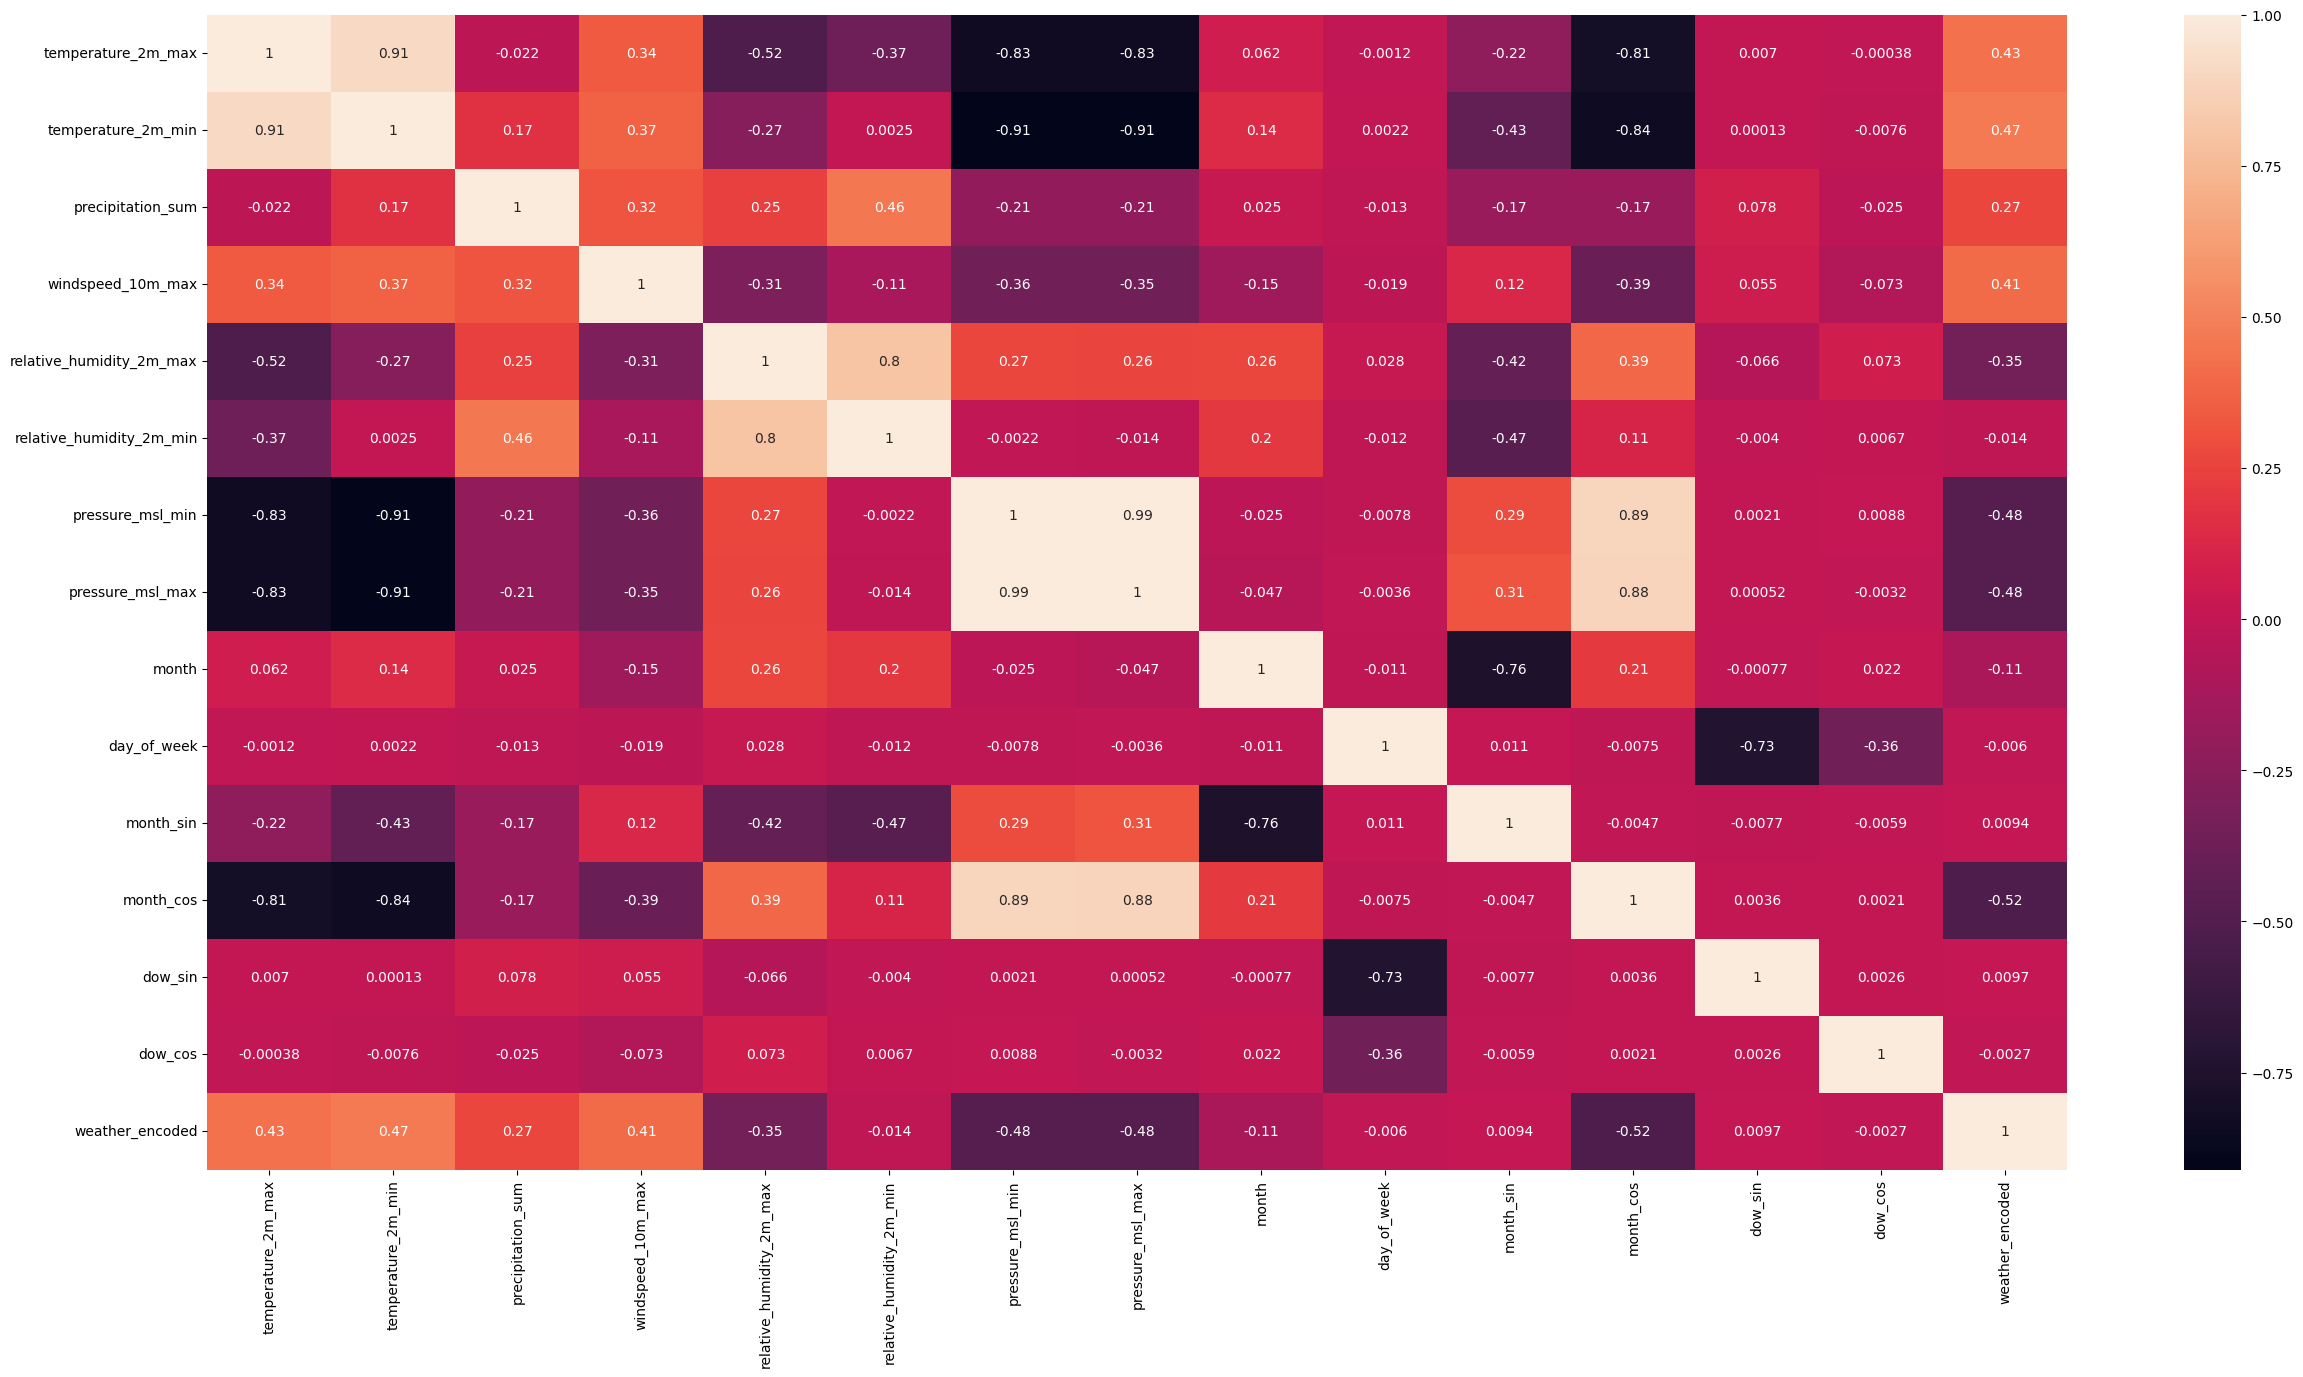

In [65]:
plt.figure(figsize=(30,15))
sns.heatmap(df.select_dtypes(include=['int','float']).corr(),annot=True)

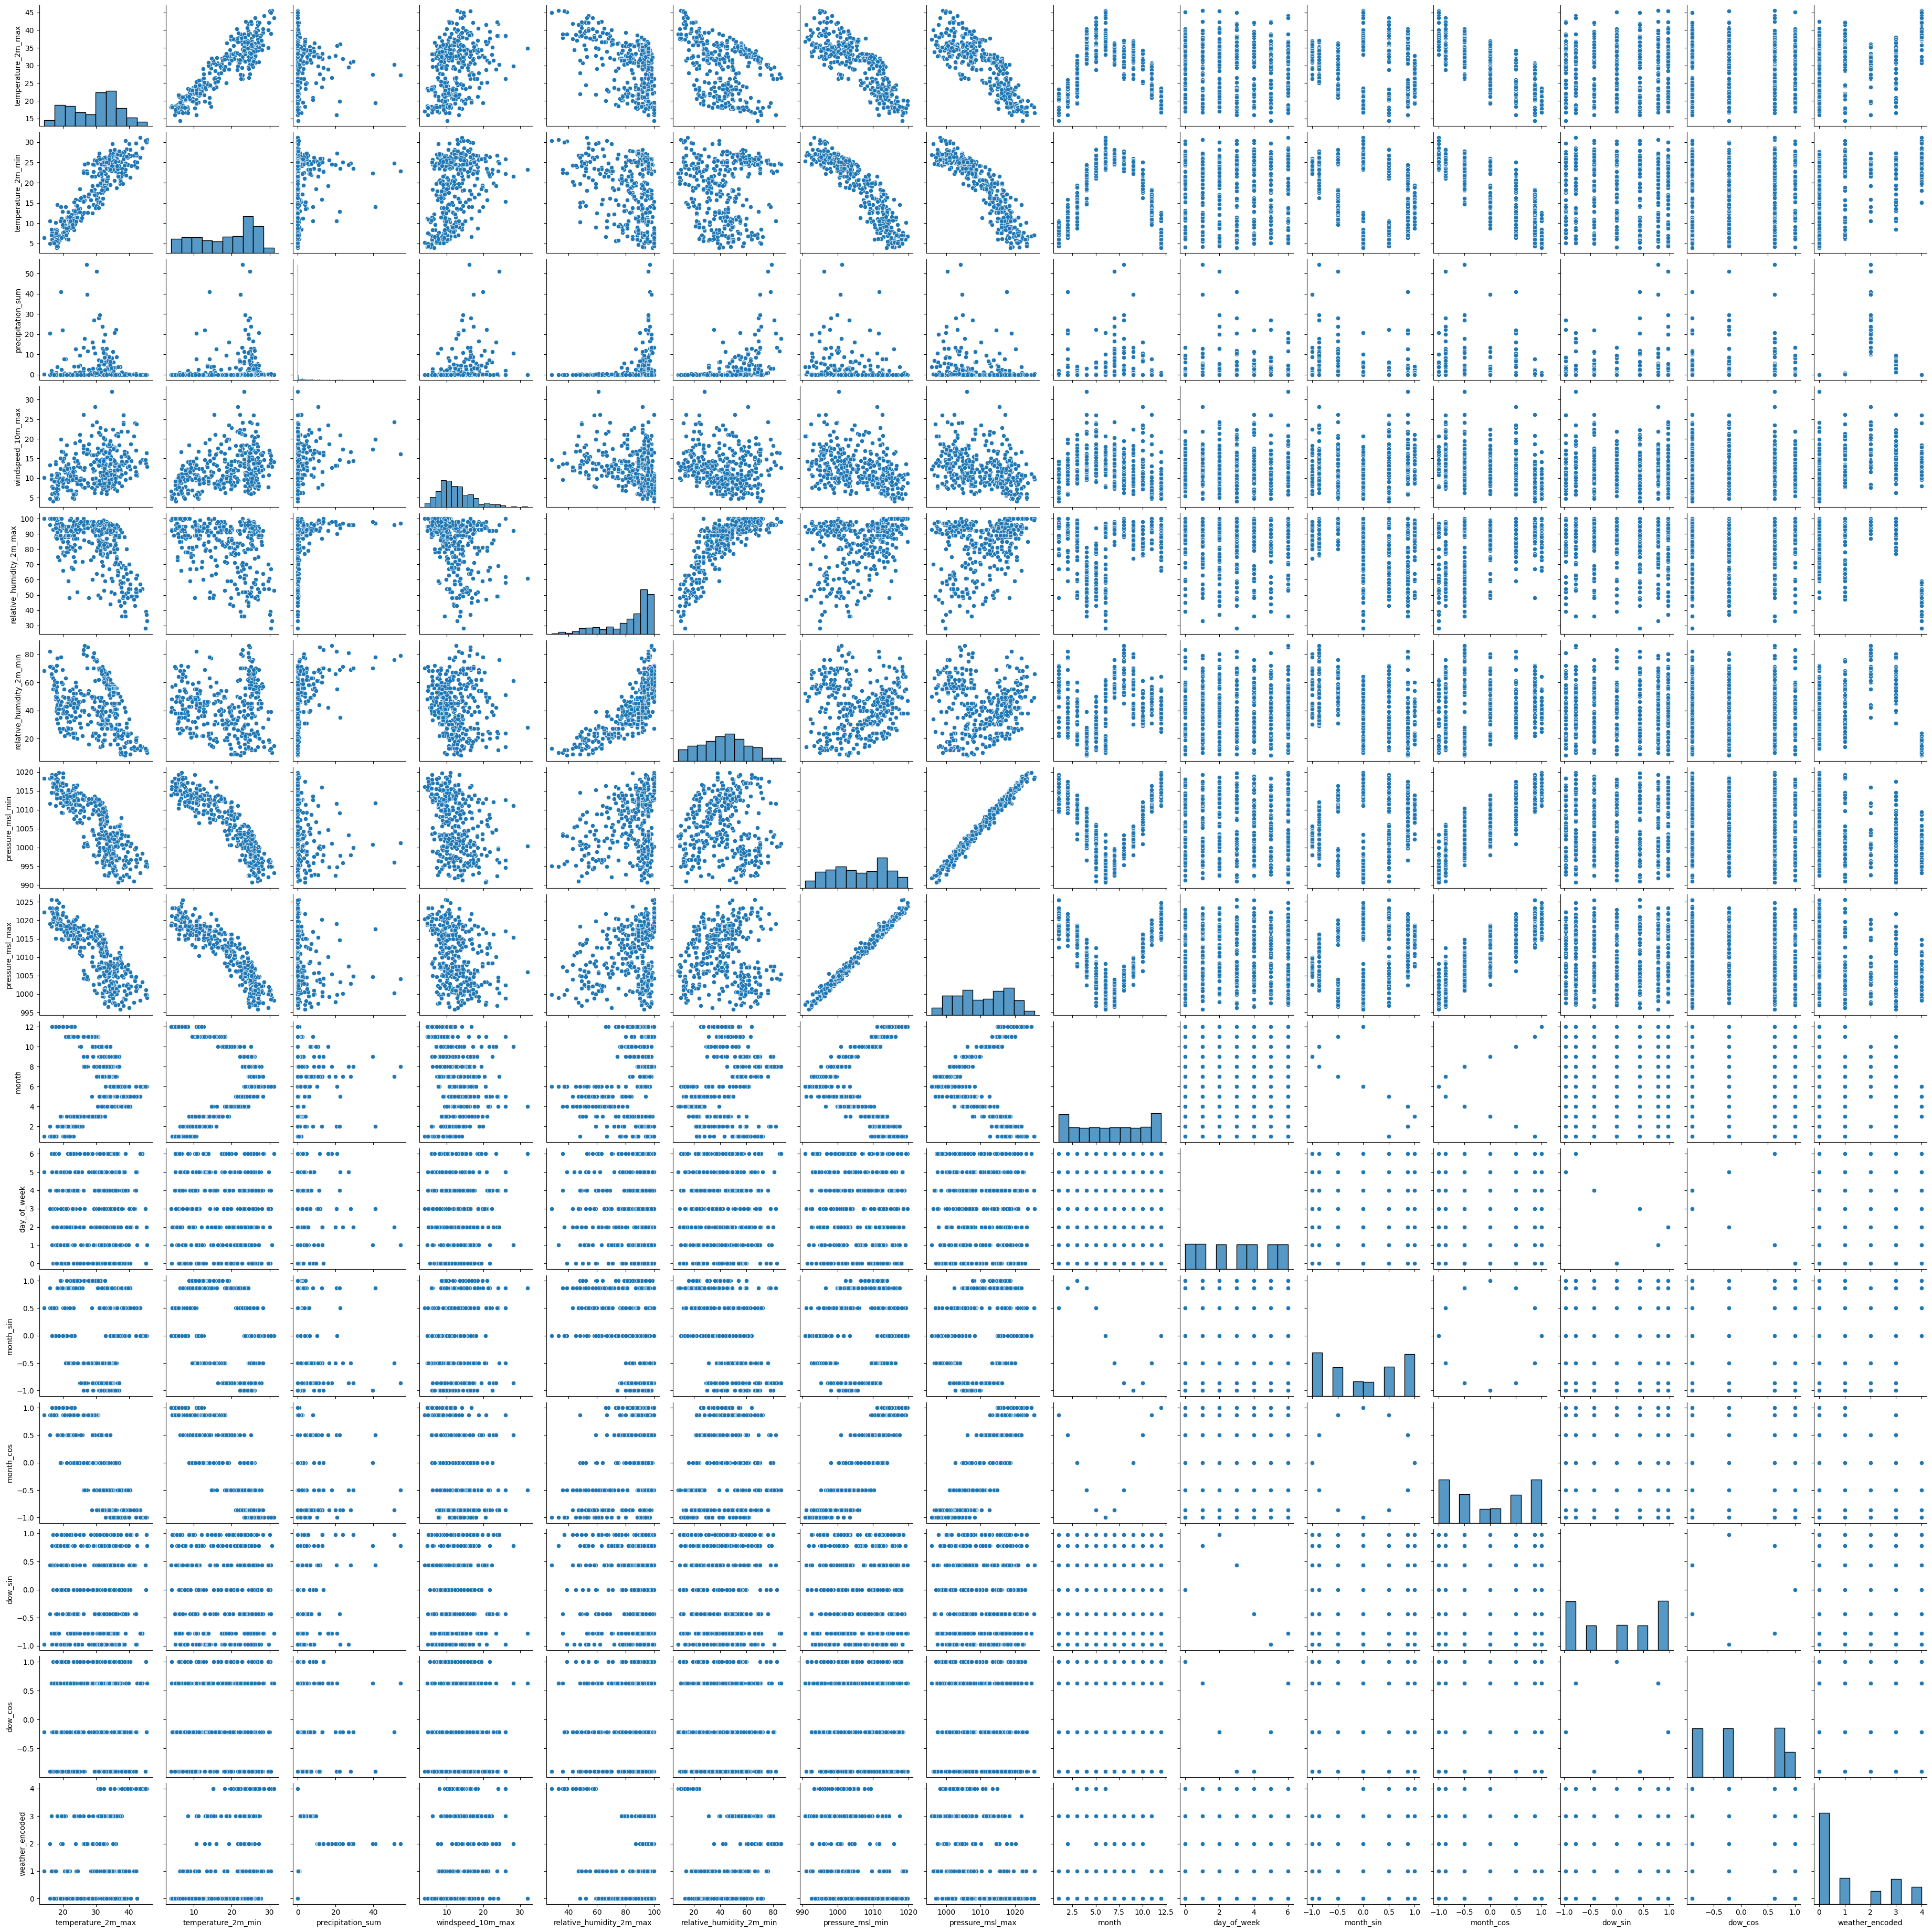

In [68]:
sns.pairplot(data=df)

In [69]:
cols=df.select_dtypes(include=[int,float])
for col in cols:
    df[col].fillna(df[col].mean(),inplace=True)
cols=df.select_dtypes(include=['category','object'])
for col in cols:
    df[col].fillna(df[col].mode()[0],inplace=True)
df.isna().sum    
    

C:\Users\World\AppData\Local\Temp\ipykernel_16780\2770746341.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(),inplace=True)
C:\Users\World\AppData\Local\Temp\ipykernel_16780\2770746341.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

<bound method DataFrame.sum of       time  temperature_2m_max  temperature_2m_min  precipitation_sum  \
0    False               False               False              False   
1    False               False               False              False   
2    False               False               False              False   
3    False               False               False              False   
4    False               False               False              False   
..     ...                 ...                 ...                ...   
361  False               False               False              False   
362  False               False               False              False   
363  False               False               False              False   
364  False               False               False              False   
365  False               False               False              False   

     windspeed_10m_max  relative_humidity_2m_max  relative_humidity_2m_min  \
0             

✅ Best Parameters: {'log_reg__C': 500, 'log_reg__class_weight': None, 'log_reg__solver': 'newton-cg'}
📊 Best Cross-Validation Accuracy: 0.9180355068856813

🎯 Test Accuracy: 0.9730

📄 Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      0.91      0.95        11
           2       1.00      0.75      0.86         4
           3       0.90      1.00      0.95         9
           4       0.88      1.00      0.93         7

    accuracy                           0.97        74
   macro avg       0.96      0.93      0.94        74
weighted avg       0.98      0.97      0.97        74



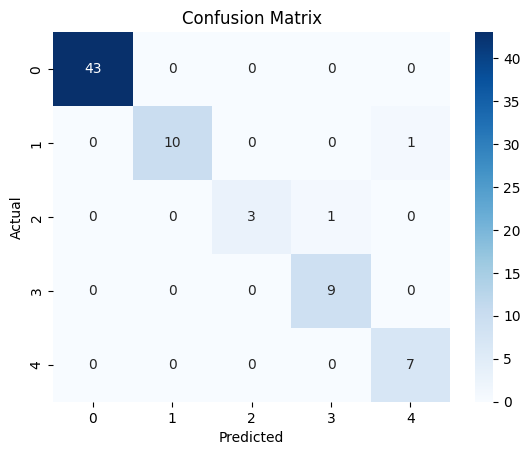

✅ Selected Features: ['precipitation_sum', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'pressure_msl_max', 'month_cos']


In [70]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ----------------------------
# 1. Feature Engineering
# ----------------------------
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek

X = df.drop(columns=["weather", "weather_encoded", "date"])
X = X.select_dtypes(include=["number"])  # keep numeric only
y = df["weather_encoded"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ----------------------------
# 2. Build Pipeline
# ----------------------------
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=5)),
    ("log_reg", LogisticRegression(max_iter=1000))
])

# ----------------------------
# 3. Hyperparameter Tuning
# ----------------------------
param_grid = {
    "log_reg__C": [0.01, 0.1, 1, 10, 100, 500],
    "log_reg__solver": ["liblinear", "lbfgs", "newton-cg", "saga"],
    "log_reg__class_weight": [None, "balanced"]
}

grid = GridSearchCV(pipe, param_grid, cv=7, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("✅ Best Parameters:", grid.best_params_)
print("📊 Best Cross-Validation Accuracy:", grid.best_score_)

# ----------------------------
# 4. Evaluate on Test Data
# ----------------------------
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(f"\n🎯 Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\n📄 Classification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ----------------------------
# 5. Show Selected Features
# ----------------------------
mask = best_model.named_steps["select"].get_support()
selected_features = X.columns[mask]
print("✅ Selected Features:", list(selected_features))
